In [1]:
import networkx as nx, pandas as pd, numpy as np

G = nx.read_edgelist("../data/facebook_combined.txt.gz", nodetype=int)
G.remove_edges_from(nx.selfloop_edges(G))

print("Nút:", G.number_of_nodes(), "| Cạnh:", G.number_of_edges())
print("Mật độ:", nx.density(G))
print("Bậc TB:", np.mean([d for _, d in G.degree()]))
print("Hệ số phân cụm TB:", nx.average_clustering(G))
print("Số thành phần liên thông:", nx.number_connected_components(G))

Nút: 4039 | Cạnh: 88234
Mật độ: 0.010819963503439287
Bậc TB: 43.69101262688784
Hệ số phân cụm TB: 0.6055467186200862
Số thành phần liên thông: 1


Nút cô lập: 0
Đường kính: 8
Độ dài đường đi TB: 3.6925068496963913
Bậc min/max/median: 1 1045 25


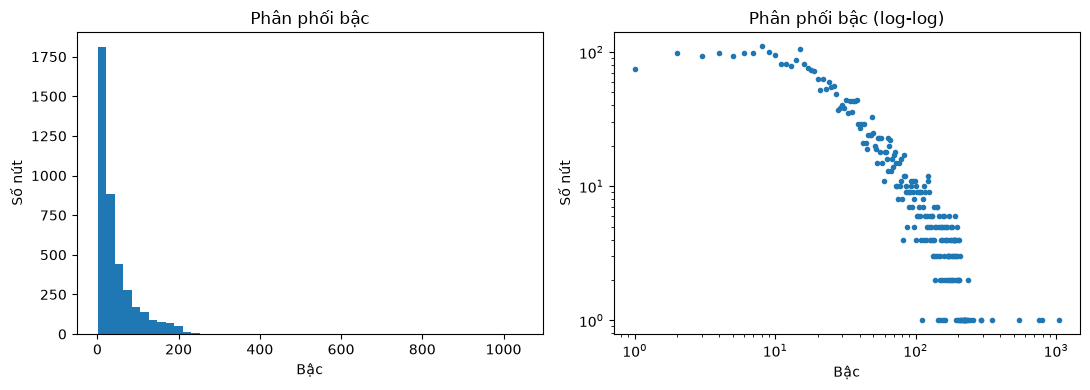

In [2]:
import matplotlib.pyplot as plt

# Làm sạch: kiểm tra cạnh trùng và nút cô lập
print("Nút cô lập:", len(list(nx.isolates(G))))

# Đường kính và độ dài đường đi trung bình
print("Đường kính:", nx.diameter(G))
print("Độ dài đường đi TB:", nx.average_shortest_path_length(G))

# Phân phối bậc
degrees = [d for _, d in G.degree()]
print("Bậc min/max/median:", min(degrees), max(degrees), int(np.median(degrees)))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(degrees, bins=50)
ax[0].set_title("Phân phối bậc")
ax[0].set_xlabel("Bậc"); ax[0].set_ylabel("Số nút")

vals, counts = np.unique(degrees, return_counts=True)
ax[1].loglog(vals, counts, "o", markersize=3)
ax[1].set_title("Phân phối bậc (log-log)")
ax[1].set_xlabel("Bậc"); ax[1].set_ylabel("Số nút")

plt.tight_layout()
plt.savefig("../figures/degree_distribution.png", dpi=200)
plt.show()